In [24]:
from scipy.optimize import newton
import numpy as np
from scipy.optimize import root_scalar

def dispersion_eq_prime(k, omega, g, H):
    return g * (np.tanh(k*H) + k*H * (1 / np.cosh(k*H))**2)

def dispersion_eq(k, omega, g, H):
    return g * k * np.tanh(k * H) - omega**2

def solve_k_brent(omega, H, g=9.81):
    f = lambda k: dispersion_eq(k, omega, g, H)
    return root_scalar(f, bracket=[1e-8, 100], method='brentq').root

def solve_k_newton(omega, H, g=9.81):
    k0 = omega / np.sqrt(g * H)  # 合理初值
    try:
        return newton(lambda k: dispersion_eq(k, omega, g, H),
                      x0=k0,
                      fprime=lambda k: dispersion_eq_prime(k, omega, g, H),
                      tol=1e-12, maxiter=20)
    except RuntimeError:
        # fallback
        return solve_k_brent(omega, H, g)

In [25]:
#################################### IMPORTS ###################################

# The usual.
import numpy as np
import numpy.polynomial as poly

################################### FUNCTION ###################################

def gravd(ω, H):
  
  g = 9.79329 # gravitational accel. for oceanic contexts
  N = len(ω)

  # Deep water approximation for k.
  k_deep = ω**2 / g

  # Initialize values of k to be solved.
  k = np.zeros(len(ω))

  # The rational approximation to tanh(x) leads to a quartic polynomial in the
  # IG dispersion relation. We solve this using poly from numpy.polynomial.
  # Conveniently, the resulting polynomial always has real roots, and now we 
  # aren't restricted to considering deep and shallow cases seperately. Poly 
  # requires we break the resulting polynomial into terms of increasing order.

  a0 = -27 * ω**2 / g                   # constant terms
  a1 = np.zeros(len(ω))                 # no linear terms
  a2 = 27 * H - (9 * ω**2 * H**2)/g     # quadratic terms
  a3 = np.zeros(len(ω))                 # no cubic terms
  a4 = np.ones(len(ω)) * H**3           # quartic terms

  # Loop over angular frequencies and compute wavenumber for each.
  for i in range(len(ω)):

    # Case when ω = 0
    if ω[i] == 0:
      k[i] = 0

    # Othwerise  
    else:
      p = poly.Polynomial([a0[i], a1[i], a2[i], a3[i], a4[i]])
      solu = poly.Polynomial.roots(p)
      positive_roots = solu[solu > 0]

      # By default we get 4 complex numbers as results, so we force the
      # real roots (i.e. those with imaginary comp == 0) to be purely real
      # numbers.
      real_positive_root = positive_roots[positive_roots.imag == 0].real[0]
      k[i] = real_positive_root
  
  # For k*H >= 2.96, prefer the deep approximation.
  for j, wavenumber in enumerate(k_deep):
    if wavenumber * H > 2.96:
      k[j] = k_deep[j]
  
  return k

In [ ]:
f = np.linspace(0.004, 0.05, 100)
w = 2 * np.pi * f
H = 5000

k_newton = np.zeros_like(w)
k_brent = np.zeros_like(w)
for i, omega in enumerate(w):
    k_newton[i] = solve_k_newton(omega, H)
    k_brent[i] = solve_k_brent(omega, H)    
print(k_newton * H)

k_mosher = gravd(w, H)

[0.08032888 0.0896837  0.09904635 0.10841763 0.11779838 0.12718944
 0.13659162 0.14600577 0.15543272 0.16487332 0.17432842 0.18379887
 0.19328553 0.20278925 0.21231092 0.22185139 0.23141156 0.24099231
 0.25059453 0.26021912 0.26986698 0.27953904 0.28923622 0.29895944
 0.30870964 0.31848777 0.32829479 0.33813167 0.34799937 0.35789889
 0.36783121 0.37779735 0.38779832 0.39783515 0.40790887 0.41802055
 0.42817124 0.43836202 0.44859398 0.45886822 0.46918586 0.47954802
 0.48995586 0.50041052 0.51091318 0.52146503 0.53206728 0.54272114
 0.55342785 0.56418867 0.57500486 0.58587771 0.59680854 0.60779865
 0.61884939 0.62996213 0.64113824 0.65237912 0.66368619 0.6750609
 0.68650469 0.69801904 0.70960547 0.72126549 0.73300065 0.7448125
 0.75670265 0.76867269 0.78072427 0.79285903 0.80507866 0.81738485
 0.82977933 0.84226386 0.85484019 0.86751013 0.88027549 0.89313812
 0.90609989 0.91916268 0.9323284  0.945599   0.95897643 0.97246268
 0.98605976 0.99976968 1.0135945  1.0275363  1.04159716 1.055779

Text(0, 0.5, 'Wave number (1/m)')

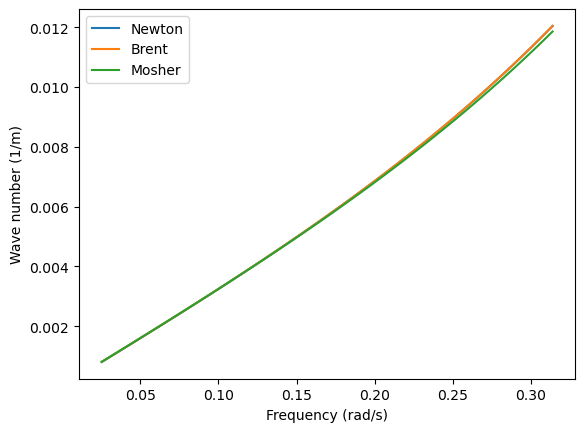

In [27]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
ax.plot(w, k_newton, label='Newton')
ax.plot(w, k_brent, label='Brent')
ax.plot(w, k_mosher, label='Mosher')
ax.legend()
ax.set_xlabel('Frequency (rad/s)')
ax.set_ylabel('Wave number (1/m)')